In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

In [2]:
wait_times = np.random.normal(loc=4.3, scale=1.2, size=35)

<pre>H0(Null Hypothesis) - average wait time at their stores is 4.0 minutes
H1(Alternastive Hypothesis) - average wait time at their stores is not 4.0 minutes(>4 or <4)
</pre>

In [3]:
t_stat, p_value = st.ttest_1samp(wait_times, popmean=4.0)

print(f"t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3f}")
alpha = 0.05
if p_value < alpha:
    print("There is sufficient evidence that the average wait time differs from 4 minutes.")
else:    
    print("There is not sufficient evidence to conclude that the average wait time differs from 4 minutes.")

t-statistic: 0.745
p-value: 0.461
There is not sufficient evidence to conclude that the average wait time differs from 4 minutes.


In [4]:
group_a = np.random.normal(loc=52, scale=12, size=50)
group_b = np.random.normal(loc=57, scale=14, size=50)

H0 - means of group_a and group_b are equal
H1 - means of group_a and group_b are not equal

In [5]:
var_a = np.var(group_a, ddof=1)
var_b = np.var(group_b, ddof=1)
levene_stat, levene_p = st.levene(group_a, group_b)

print(f"Variance for Group A: {var_a:.3f}")
print(f"Variance for Group B: {var_b:.3f}")
print(f"Levene's test statistic: {levene_stat:.3f}")
print(f"Levene's test p-value: {levene_p:.3f}")

Variance for Group A: 136.060
Variance for Group B: 169.254
Levene's test statistic: 0.139
Levene's test p-value: 0.710


In [6]:
t_test_stat, t_test_p = st.ttest_ind(group_a, group_b, equal_var=False)
print(f"t-test statistic: {t_test_stat:.3f}")
print(f"t-test p-value: {t_test_p:.3f}")

t-test statistic: -2.261
t-test p-value: 0.026


<pre>
The A/B test shows that the new checkout design (Group B) led to higher average order values than the old design (Group A).
The difference is statistically significant (p = 0.026), so it’s unlikely to be due to chance.
This means the streamlined checkout is more effective and could increase revenue.
</pre>

In [7]:
before = np.random.normal(loc=70, scale=8, size=30)
after = before + np.random.normal(loc=3, scale=5, size=30)

<pre>As the same employees are measured before and after, this is paired data, and we want to see if the new workflow tool improves productivity.
We can justify a one-tailed test because our research question is directional - we are testing if the tool increases productivity, not just changes it.
H0 - the tool does not increase productivity
H1 - the tool increases productivity
</pre>

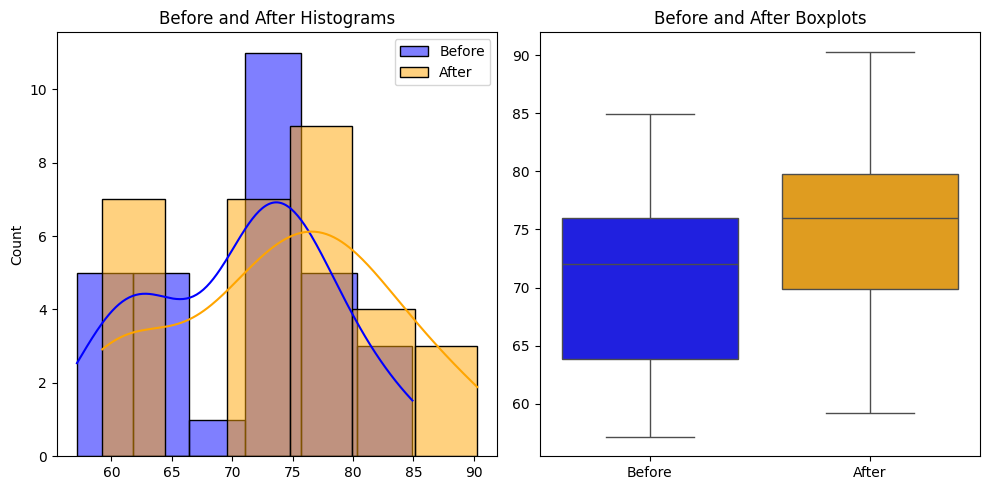

In [8]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.histplot(before, kde=True, color='blue', label='Before')
sns.histplot(after, kde=True, color='orange', label='After')
plt.legend()
plt.title("Before and After Histograms")        
plt.subplot(1, 2, 2)
sns.boxplot(data=[before, after], palette=['blue', 'orange'])
plt.xticks([0, 1], ['Before', 'After'])
plt.title("Before and After Boxplots")
plt.tight_layout()
plt.show()

In [10]:
t_paired, p_paired = st.ttest_rel(after, before)
print(f"Paired t-test statistic: {t_paired:.3f}")
print(f"Paired t-test p-value: {p_paired:.4f}")

Paired t-test statistic: 4.079
Paired t-test p-value: 0.0003


<pre>The paired t-test gave a t-statistic of 4.079 and a p-value < 0.001. 
Since the p-value is much smaller than 0.05, we reject the null hypothesis.
In plain language: the new workflow tool significantly increased employee productivity. 
The improvement in scores after using the tool is unlikely to have happened by chance, so the tool appears to be effective.
</pre>